# Supervised classification with chronological cross-validation

## Purpose and scope
This supplementary experiment compares **logistic regression** and a **random forest classifier**, using a small hyperparameter grid and two expanding, time-ordered validation folds. It addresses whether labeled historical patterns transfer to later observations. Unlike the earlier unsupervised experiments, annotation-window labels are used for supervised training.

The original results remain unchanged. This is a **retrospective extension**: the source series and some later periods have already been inspected in earlier work. The evaluation is held out from this grid search, but is not a newly acquired, untouched external test.

**Decision rule fixed before running:** select hyperparameters and the model family by mean validation F1, then evaluate both selected configurations once on the later test period. A probability threshold of 0.5 is fixed. No test-based retuning follows. F1 balances precision and recall; false-positive counts and recall must also be examined because a good average does not establish an acceptable alerting policy.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score, confusion_matrix

ROOT = Path.cwd().resolve()
if not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
assert (ROOT / 'requirements.txt').exists()
RAW = ROOT / 'data/raw/nab'
OUT = ROOT / 'data/processed/validation'
FIG = ROOT / 'reports/figures'
for directory in [OUT, FIG]:
    directory.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid')

## Data and feature preparation
Use the same eight NAB series. Drop invalid entries and duplicate timestamps, sort each series, and construct six numeric features using the current and strictly preceding measurements. Drop 12 initial rows per cleaned series. The series identifier is a categorical predictor, encoded within each training fold. This identifies the signal source, not its anomaly label.

The eight series cover different calendar periods and measurement units. Models are pooled across series; scaling and encoding are fitted only on training rows. This creates a difficult transfer test and is not directly comparable with the per-series splits in the original experiments.

In [2]:
sources = {
    'ec2_cpu_utilization_5f5533': 'realAWSCloudwatch',
    'ec2_cpu_utilization_24ae8d': 'realAWSCloudwatch',
    'ec2_cpu_utilization_53ea38': 'realAWSCloudwatch',
    'ec2_request_latency_system_failure': 'realKnownCause',
    'cpu_utilization_asg_misconfiguration': 'realKnownCause',
    'ec2_cpu_utilization_825cc2': 'realAWSCloudwatch',
    'ec2_network_in_257a54': 'realAWSCloudwatch',
    'elb_request_count_8c0756': 'realAWSCloudwatch',
}
annotations = json.loads((RAW / 'anomaly_windows.json').read_text())
numeric = ['value', 'past_mean', 'past_std', 'lag_1', 'lag_3', 'change']
frames, inventory = [], []
for series, folder in sources.items():
    data = pd.read_csv(RAW / f'{series}.csv')
    original_rows = len(data)
    data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce')
    data['value'] = pd.to_numeric(data['value'], errors='coerce')
    data = data.dropna(subset=['timestamp', 'value']).drop_duplicates('timestamp')
    data = data.sort_values('timestamp').reset_index(drop=True)
    cleaned_rows = len(data)
    previous = data['value'].shift(1)
    data['past_mean'] = previous.rolling(12).mean()
    data['past_std'] = previous.rolling(12).std()
    data['lag_1'] = previous
    data['lag_3'] = data['value'].shift(3)
    data['change'] = data['value'] - previous
    data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=numeric)
    data['series'] = series
    data['label'] = 0
    for start, end in annotations[f'{folder}/{series}.csv']:
        data.loc[data['timestamp'].between(pd.Timestamp(start), pd.Timestamp(end)), 'label'] = 1
    frames.append(data)
    inventory.append({'series': series, 'raw_rows': original_rows, 'cleaned_rows': cleaned_rows,
                      'usable_rows': len(data), 'labeled_rows': int(data.label.sum())})
panel = pd.concat(frames, ignore_index=True).sort_values(['timestamp', 'series']).reset_index(drop=True)
assert not panel.duplicated(['series', 'timestamp']).any()
assert panel[numeric].notna().all().all()
display(pd.DataFrame(inventory))

,series,raw_rows,cleaned_rows,usable_rows,labeled_rows
0,ec2_cpu_utilization_5f5533,4032,4032,4020,402
1,ec2_cpu_utilization_24ae8d,4032,4032,4020,402
2,ec2_cpu_utilization_53ea38,4032,4032,4020,402
3,ec2_request_latency_system_failure,4032,4021,4009,346
4,cpu_utilization_asg_misconfiguration,18050,18050,18038,1499
5,ec2_cpu_utilization_825cc2,4032,4032,4020,343
6,ec2_network_in_257a54,4032,4032,4020,403
7,elb_request_count_8c0756,4032,4032,4020,402


## Holdout and forward validation design
Reserve the latest approximately 20% of observations by **global calendar time**, keeping all rows sharing a timestamp on the same side. Training therefore never uses later-calendar observations from another series to predict earlier ones.

Within development data, fold 1 trains on the earliest quarter and validates on the next quarter; fold 2 trains on the earliest half and validates on the next quarter. A one-hour gap separates fitting and validation (and development from the final test). The final development quarter remains available for refitting after selection. Folds have unequal calendar durations because data density changes. Two folds provide limited uncertainty evidence; fold scores are descriptive, not confidence intervals.

The latest global test period contains only the ASG CPU series. Consequently, the test cannot establish performance across all eight signals. This is displayed before fitting rather than hidden in an aggregate result.

In [3]:
cut_time = panel.iloc[int(len(panel) * 0.80)]['timestamp']
gap = pd.Timedelta(hours=1)
development = panel.loc[panel.timestamp < cut_time - gap].reset_index(drop=True)
test = panel.loc[panel.timestamp >= cut_time].reset_index(drop=True)
features = numeric + ['series']
X_dev, y_dev = development[features], development['label']
X_test, y_test = test[features], test['label']
folds, fold_rows = [], []
for fold, (start_fraction, end_fraction) in enumerate([(0.25, 0.50), (0.50, 0.75)], 1):
    start = development.iloc[int(len(development) * start_fraction)]['timestamp']
    end = development.iloc[int(len(development) * end_fraction)]['timestamp']
    train_idx = np.flatnonzero((development.timestamp < start - gap).to_numpy())
    valid_idx = np.flatnonzero(((development.timestamp >= start) & (development.timestamp < end)).to_numpy())
    assert development.iloc[train_idx].timestamp.max() < development.iloc[valid_idx].timestamp.min() - gap
    assert y_dev.iloc[train_idx].nunique() == y_dev.iloc[valid_idx].nunique() == 2
    folds.append((train_idx, valid_idx))
    fold_rows.append({'fold': fold, 'train_rows': len(train_idx), 'validation_rows': len(valid_idx),
                      'train_positives': int(y_dev.iloc[train_idx].sum()),
                      'validation_positives': int(y_dev.iloc[valid_idx].sum()),
                      'train_end': str(development.iloc[train_idx].timestamp.max()),
                      'validation_start': str(development.iloc[valid_idx].timestamp.min()),
                      'validation_end': str(development.iloc[valid_idx].timestamp.max())})
assert development.timestamp.max() < test.timestamp.min() - gap
display(pd.DataFrame(fold_rows))
display(test.groupby('series').agg(test_rows=('label', 'size'), labeled_rows=('label', 'sum')))
print('Development rows:', len(development), '| Test rows:', len(test), '| Test begins:', cut_time)

,fold,train_rows,validation_rows,train_positives,validation_positives,train_end,validation_start,validation_end
0,1,9193,9231,804,874,2014-02-25 06:47:00,2014-02-25 07:50:00,2014-04-12 19:29:00
1,2,18424,9228,1666,1022,2014-04-12 18:29:00,2014-04-12 19:34:00,2014-04-23 12:04:00


,test_rows,labeled_rows
series,,
cpu_utilization_asg_misconfiguration,9234,1499


Development rows: 36921 | Test rows: 9234 | Test begins: 2014-06-13 15:54:00


## Models, parameter grids and leakage controls
Logistic regression provides a simple linear classification reference. Random forest can capture nonlinear feature combinations. All scaling and category encoding are inside each pipeline and are refitted in every fold. Unknown series categories are ignored safely by the encoder.

The logistic grid has six combinations: strength parameter C in {0.1, 1, 10}, and class weighting in {none, balanced}. The forest grid has four combinations: maximum depth in {4, 8}, minimum leaf size in {5, 20}, with 100 trees and balanced class weights fixed. Ten configurations × two folds = 20 validation fits, plus one refit per model family. This bounded grid demonstrates systematic selection; it is not an exhaustive search.

Selection uses mean fold F1. Precision and recall are reported alongside it. Accuracy is not the selection metric because mostly normal periods could make an ineffective detector look successful.

In [4]:
def preprocessing():
    return ColumnTransformer([
        ('numeric', RobustScaler(), numeric),
        ('series', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['series']),
    ])

experiments = {
    'Logistic regression': (
        Pipeline([('prepare', preprocessing()), ('model', LogisticRegression(max_iter=3000, random_state=SEED))]),
        {'model__C': [0.1, 1.0, 10.0], 'model__class_weight': [None, 'balanced']},
    ),
    'Random forest': (
        Pipeline([('prepare', preprocessing()), ('model', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=1))]),
        {'model__max_depth': [4, 8], 'model__min_samples_leaf': [5, 20]},
    ),
}
scoring = {
    'f1': make_scorer(f1_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
}
searches, selection_rows, grids = {}, [], []
for name, (pipeline, parameters) in experiments.items():
    search = GridSearchCV(pipeline, parameters, scoring=scoring, refit='f1', cv=folds,
                          n_jobs=1, error_score='raise', return_train_score=False)
    search.fit(X_dev, y_dev)
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    results.insert(0, 'model', name)
    grids.append(results)
    best = results.iloc[search.best_index_]
    selection_rows.append({'model': name, 'configurations': len(list(ParameterGrid(parameters))),
                           'mean_cv_f1': search.best_score_,
                           'fold_1_f1': best['split0_test_f1'], 'fold_2_f1': best['split1_test_f1'],
                           'best_parameters': json.dumps(search.best_params_)})
selection = pd.DataFrame(selection_rows)
winner = selection.sort_values(['mean_cv_f1', 'model'], ascending=[False, True]).iloc[0]['model']
display(selection)
print('Selected using validation only:', winner)

,model,configurations,mean_cv_f1,fold_1_f1,fold_2_f1,best_parameters
0,Logistic regression,6,0.096429,0.044907,0.147951,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
1,Random forest,4,0.141813,0.106036,0.177590,"{""model__max_depth"": 8, ""model__min_samples_le..."


Selected using validation only: Random forest


## Later-period evaluation after selection
Both selected configurations are evaluated once. The validation winner is identified before this step. A classifier can make no positive predictions; in that case precision is reported as undefined rather than presented as successful accuracy. F1 is zero when all labeled anomalies are missed. Prediction files retain every observation for independent recalculation.

In [5]:
evaluation, predictions = [], []
for name, search in searches.items():
    predicted = search.predict(X_test)
    probability = search.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    evaluation.append({'model': name, 'selected_by_cv': name == winner,
                       'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
                       'precision': tp/(tp+fp) if tp+fp else np.nan,
                       'recall': tp/(tp+fn), 'f1': 2*tp/(2*tp+fp+fn),
                       'false_positive_rate': fp/(fp+tn)})
    block = test[['timestamp', 'series', 'value', 'label']].copy()
    block['model'] = name
    block['prediction'] = predicted
    block['probability'] = probability
    predictions.append(block)
evaluation = pd.DataFrame(evaluation)
display(evaluation.round(4))
selection.to_csv(OUT/'model_selection.csv', index=False)
evaluation.to_csv(OUT/'test_metrics.csv', index=False)
pd.concat(grids, ignore_index=True).to_csv(OUT/'grid_search_results.csv', index=False)
pd.concat(predictions, ignore_index=True).to_csv(OUT/'test_predictions.csv', index=False)
pd.DataFrame(fold_rows).to_csv(OUT/'folds.csv', index=False)
pd.DataFrame(inventory).to_csv(OUT/'data_inventory.csv', index=False)

,model,selected_by_cv,TP,FP,FN,TN,precision,recall,f1,false_positive_rate
0,Logistic regression,False,0,0,1499,7735,NaN,0.0,0.0,0.0
1,Random forest,True,0,0,1499,7735,NaN,0.0,0.0,0.0


## Visual comparison
The left chart shows the two validation-fold scores separately, exposing instability instead of hiding it in an average. The right chart shows F1 on the later global test period. These are different periods, so the charts describe transfer performance rather than a paired statistical test.

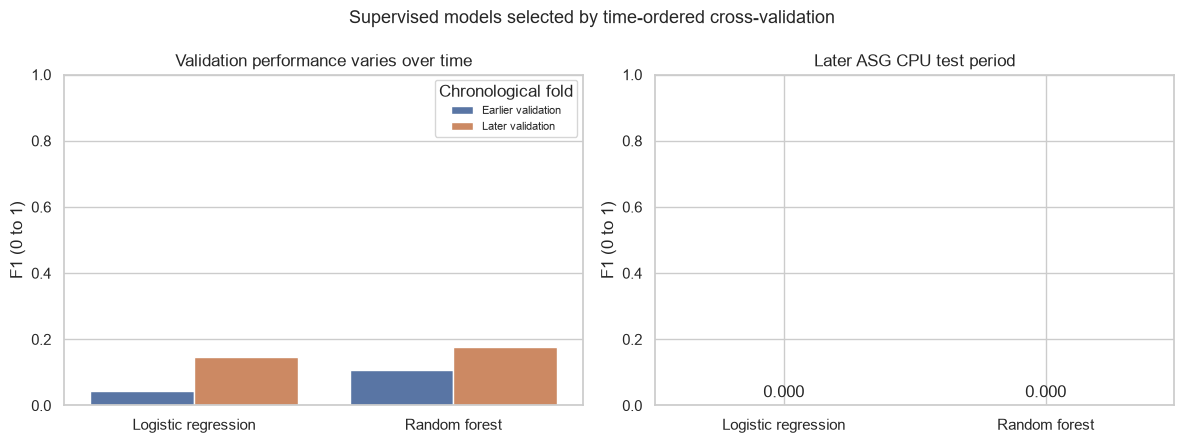

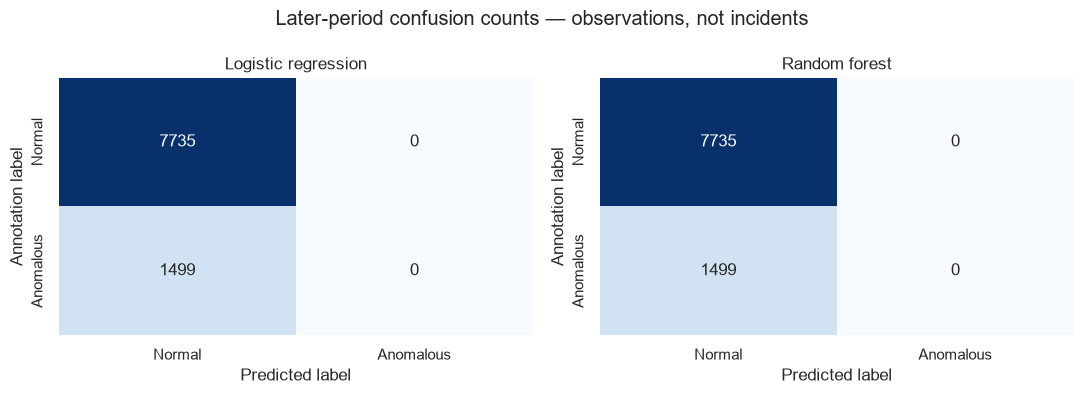

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
long = selection.melt(id_vars='model', value_vars=['fold_1_f1', 'fold_2_f1'], var_name='fold', value_name='F1')
long['fold'] = long['fold'].map({'fold_1_f1': 'Earlier validation', 'fold_2_f1': 'Later validation'})
sns.barplot(data=long, x='model', y='F1', hue='fold', ax=axes[0])
axes[0].set(title='Validation performance varies over time', xlabel='', ylabel='F1 (0 to 1)', ylim=(0, 1))
axes[0].legend(title='Chronological fold', fontsize=8)
axes[1].bar(evaluation['model'], evaluation['f1'], color=['#254e70', '#b47724'])
axes[1].set(title='Later ASG CPU test period', xlabel='', ylabel='F1 (0 to 1)', ylim=(0, 1))
for i, row in evaluation.iterrows():
    axes[1].text(i, row.f1 + .025, f'{row.f1:.3f}', ha='center')
fig.suptitle('Supervised models selected by time-ordered cross-validation', fontsize=13)
fig.tight_layout()
fig.savefig(FIG/'supervised_validation.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (_, row) in zip(axes, evaluation.iterrows()):
    matrix = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype=int)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'Anomalous'], yticklabels=['Normal', 'Anomalous'])
    ax.set(title=row.model, xlabel='Predicted label', ylabel='Annotation label')
fig.suptitle('Later-period confusion counts — observations, not incidents')
fig.tight_layout()
fig.savefig(FIG/'supervised_confusion_counts.png', dpi=180, bbox_inches='tight')
plt.show()

## Findings, limitations and next steps

Random forest was selected with mean validation F1 of **0.1418**, compared with **0.0964** for logistic regression. Its fold scores were 0.1060 and 0.1776. On the later ASG test period, **both models missed all 1,499 labeled observations** and made no positive predictions: recall and F1 were 0, while precision was undefined. The 7,735 normal-labeled readings were all unflagged. Low false-alarm volume therefore does not establish useful detection.


Two chronological validation folds are a limited sample and cover different series mixes. The final test covers only ASG CPU, and ASG anomalies occur late, outside supervised training. Any failure on this period is evidence of a limitation, not a reason to tune on its labels. Because prior work inspected this dataset, the experiment remains retrospective.

**Action:** retain the original statistical and unsupervised comparisons, collect incident-reviewed labels on additional unseen workloads, and validate a candidate against explicit alert-noise and detection targets before deployment. Neither classification scores nor benchmark windows establish incident recovery-time or cost savings.

Implementation reference: [scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). Data: [Numenta Anomaly Benchmark](https://github.com/numenta/NAB).